# Lithology Classification from Well Logs (FORCE 2020, North Sea)

Predict rock type at every depth from wireline logs, using gradient boosting and **validation by well** (never by random rows).

- **Data:** FORCE 2020 well log and lithofacies dataset, 118 wells, Norwegian Sea (Zenodo DOI 10.5281/zenodo.4351156, CC BY 4.0).
- **Metric:** macro-F1. Accuracy is misleading because Shale is ~61% of labelled rows.
- **Runtime:** the first full run takes a while (download, parsing 118 LAS files, feature building, cross-validation). Re-running experiments is optional, see `RUN_ALL_EXPERIMENTS`.

> Personal learning project. Scores are my own evaluation and are not comparable to the official competition leaderboard.

## 0. Setup

In [1]:
!pip install -q lasio

import os, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lasio
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

LABEL = "FORCE_2020_LITHOFACIES_LITHOLOGY"
CONF = "FORCE_2020_LITHOFACIES_CONFIDENCE"

# NOTE: code -> name mapping written from memory of the competition docs.
# Please verify against the official FORCE 2020 repository before publishing.
LITHO_MAP = {
    30000: "Sandstone", 65030: "Sandstone/Shale", 65000: "Shale",
    80000: "Marl", 74000: "Dolomite", 70000: "Limestone",
    70032: "Chalk", 88000: "Halite", 86000: "Anhydrite",
    99000: "Tuff", 90000: "Coal", 93000: "Basement",
}
BASE = ["GR", "RHOB", "NPHI", "DTC", "PEF", "RDEP", "RMED", "SP", "CALI"]

RUN_ALL_EXPERIMENTS = False   # True re-runs every experiment of the log (can take 40+ min)
CACHE = "/content/force2020_merged.parquet"

## 1. Download and merge the data (118 LAS files)

In [2]:
URL = "https://zenodo.org/records/4351156/files/LAS_files_Force_2020_all_wells_train_test_blind_hidden_final.zip?download=1"
if not os.path.exists("force2020"):
    !wget -q -O force2020.zip "$URL"
    !unzip -q -o force2020.zip -d force2020

sip


In [3]:
if os.path.exists(CACHE):
    df = pd.read_parquet(CACHE)
else:
    files = sorted(glob.glob("force2020/**/*.las", recursive=True) + glob.glob("force2020/**/*.LAS", recursive=True))
    print("LAS files:", len(files))
    frames = []
    for f in files:
        d = lasio.read(f).df().reset_index()
        d["WELL"] = os.path.basename(f).rsplit(".", 1)[0]
        frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    df.to_parquet(CACHE)   # local cache for this session

print(f"Total rows: {len(df):,} | wells: {df['WELL'].nunique()}")
df.head()

LAS files: 118
Total rows: 2,337,639 | wells: 118


,DEPT,FORCE_2020_LITHOFACIES_CONFIDENCE,FORCE_2020_LITHOFACIES_LITHOLOGY,CALI,MUDWEIGHT,ROP,RDEP,RSHA,RMED,RXO,...,X_LOC,Y_LOC,Z_LOC,WELL,BS,DCAL,SGR,ROPA,DTS,RMIC
0,25.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,15_9-13,NaN,NaN,NaN,NaN,NaN,NaN
1,25.152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,15_9-13,NaN,NaN,NaN,NaN,NaN,NaN
2,25.304,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,15_9-13,NaN,NaN,NaN,NaN,NaN,NaN
3,25.456,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,15_9-13,NaN,NaN,NaN,NaN,NaN,NaN
4,25.608,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,15_9-13,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Exploratory data analysis

Three things to check: how imbalanced the classes are, how much data is missing, and how reliable the labels are.

Labelled rows: 1,431,383 | wells with labels: 118


,rows,percent
LITHO,,
Shale,877043,61.27
Sandstone,207704,14.51
Sandstone/Shale,180820,12.63
Limestone,69498,4.86
Marl,41038,2.87
Tuff,17431,1.22
Halite,14712,1.03
Chalk,14043,0.98
Coal,4754,0.33


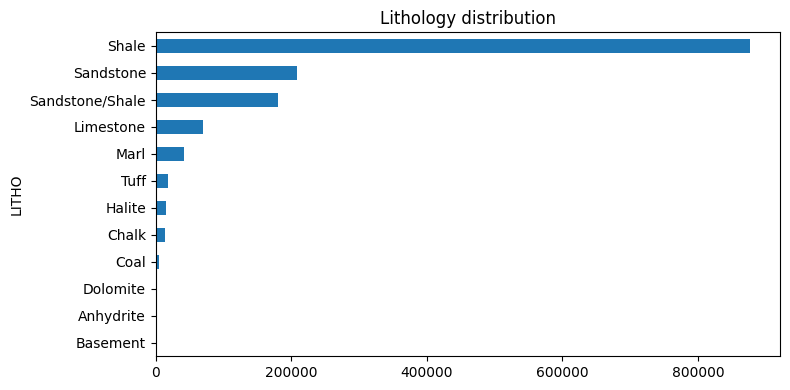

In [4]:
lab = df.dropna(subset=[LABEL]).copy()
lab["LITHO"] = lab[LABEL].astype(int).map(LITHO_MAP)
print(f"Labelled rows: {len(lab):,} | wells with labels: {lab['WELL'].nunique()}")

dist = lab["LITHO"].value_counts(dropna=False).to_frame("rows")
dist["percent"] = (dist["rows"] / dist["rows"].sum() * 100).round(2)
display(dist)

ax = dist["rows"].plot.barh(figsize=(8, 4), title="Lithology distribution")
ax.invert_yaxis()
plt.tight_layout(); plt.savefig("class_distribution.png", dpi=150); plt.show()

In [5]:
print("Missing % per curve (labelled rows):")
print((lab[BASE].isna().mean() * 100).round(1).sort_values(ascending=False))

avail = lab.groupby("WELL")[BASE].apply(lambda g: g.notna().mean())
print("\nWells with the curve >50% filled (out of", lab["WELL"].nunique(), "):")
print((avail > 0.5).sum())

print("\nLabel confidence level by class (row-normalised):")
print(pd.crosstab(lab["LITHO"], lab[CONF], normalize="index").round(2))

Missing % per curve (labelled rows):
PEF     38.1
NPHI    32.4
SP      31.6
RHOB    13.2
CALI     6.8
DTC      6.1
RMED     3.5
RDEP     0.8
GR       0.1
dtype: float64

Wells with the curve >50% filled (out of 118 ):
GR      118
RHOB    109
NPHI     92
DTC     114
PEF      74
RDEP    118
RMED    116
SP       70
CALI    109
dtype: int64

Label confidence level by class (row-normalised):
FORCE_2020_LITHOFACIES_CONFIDENCE   1.0   2.0   3.0
LITHO                                              
Anhydrite                          0.86  0.12  0.03
Basement                           0.63  0.16  0.21
Chalk                              0.72  0.21  0.07
Coal                               0.89  0.11  0.00
Dolomite                           0.75  0.17  0.08
Halite                             0.72  0.26  0.02
Limestone                          0.82  0.17  0.01
Marl                               0.76  0.23  0.01
Sandstone                          0.92  0.07  0.01
Sandstone/Shale                    0.8

**Takeaways.** Shale dominates; several classes have under 1% of rows (Basement: 141 rows). Missing data is *per well* (whole curves absent), so mean imputation would mislead. Tree-based models that accept NaN natively avoid that problem. Almost all Tuff labels carry the lowest confidence level, which matters later when filtering by confidence.

## 3. Feature engineering

- 9 log curves, resistivities (RDEP, RMED) log10-transformed.
- Context features per well: rolling mean/std and a 5-sample difference for GR, RHOB, NPHI, DTC. Sample spacing is about 0.15 m, so windows of 5 and 25 samples cover roughly 0.75 m and 4 m.
- Coordinates and depth are deliberately **not** used, so the model cannot memorise well locations.

In [6]:
def build_feats(windows):
    d2 = df.sort_values(["WELL", "DEPT"]).copy()
    for c in ["RDEP", "RMED"]:
        d2[c] = np.log10(d2[c].where(d2[c] > 0))
    g = d2.groupby("WELL")
    new = {}
    for c in ["GR", "RHOB", "NPHI", "DTC"]:
        for w in windows:
            r = g[c].rolling(w, center=True, min_periods=3)
            new[f"{c}_mean{w}"] = r.mean().reset_index(level=0, drop=True)
            new[f"{c}_std{w}"] = r.std().reset_index(level=0, drop=True)
        new[f"{c}_diff5"] = g[c].diff(5)
    d2 = pd.concat([d2, pd.DataFrame(new)], axis=1)
    return d2, BASE + list(new.keys())

_cache = {}
def get_feats(windows):
    """Keep only one feature table in memory at a time."""
    key = tuple(windows)
    if key not in _cache:
        _cache.clear()
        _cache[key] = build_feats(windows)
    return _cache[key]

## 4. Validation helpers

Everything is split **by well** (`GroupKFold`). Training rows are subsampled (every `stride`-th row) because neighbouring samples in a well are nearly identical. Class imbalance is handled with sample weights proportional to `(1 / class frequency) ** power`: `power=1` is close to fully balanced, smaller values are softer.

In [7]:
def make_weights(y, power):
    cnt = y.map(y.value_counts())
    w = (1.0 / cnt) ** power
    return (w / w.mean()).values

def run_cv(d2, feats, power=0.75, balanced=False, conf_max=None,
           stride=6, max_iter=100, n_splits=5):
    dd = d2.dropna(subset=[LABEL]).reset_index(drop=True)
    X, y, groups, conf = dd[feats], dd[LABEL].astype(int), dd["WELL"], dd[CONF]
    yt, yp = [], []
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        if conf_max is not None:                     # filter training data only
            tr = tr[(conf.iloc[tr] <= conf_max).values]
        tr = tr[::stride]
        ytr = y.iloc[tr]
        if balanced:
            m = HistGradientBoostingClassifier(max_iter=max_iter, learning_rate=0.1,
                    class_weight="balanced", random_state=RANDOM_STATE)
            m.fit(X.iloc[tr], ytr)
        else:
            m = HistGradientBoostingClassifier(max_iter=max_iter, learning_rate=0.1,
                    random_state=RANDOM_STATE)
            m.fit(X.iloc[tr], ytr, sample_weight=make_weights(ytr, power))
        yt.append(y.iloc[te].values)
        yp.append(m.predict(X.iloc[te]))
    return np.concatenate(yt), np.concatenate(yp)

def summarize(name, yt, yp):
    print(f"{name}: macro-F1 = {f1_score(yt, yp, average='macro'):.3f} | acc = {(yt == yp).mean():.3f}")

## 5. Baseline and experiment log

First the naive baseline: always predict Shale. High accuracy, near-zero macro-F1.

In [8]:
y_all = lab[LABEL].astype(int)
base_pred = np.full(len(y_all), 65000)
print("Always-Shale baseline | macro-F1 =", round(f1_score(y_all, base_pred, average="macro"), 3),
      "| acc =", round((y_all == 65000).mean(), 3))

Always-Shale baseline | macro-F1 = 0.063 | acc = 0.613


### Recorded results of the experiment log (5-fold grouped CV)

These numbers were recorded in earlier runs of this notebook. Run 1 used `stride=4, max_iter=150`; the others used `stride=6, max_iter=100`, so comparisons are approximate. Each row is a single run with no variance estimate, and the final configuration was chosen on this same CV, so its score is somewhat optimistic.

In [9]:
recorded = pd.DataFrame([
    ("0", "Always predict Shale",                           0.063, "~0.61"),
    ("1", "9 raw curves, class_weight=balanced",            0.337, "0.57"),
    ("2", "+ rolling (25, 100), balanced",                  0.369, "0.62"),
    ("3", "Windows (25, 100), weights power 0.5",           0.387, "0.70"),
    ("4", "Windows (5, 25), weights power 0.5",             0.399, "0.69"),
    ("5", "Windows (5, 25), weights power 0.75  [final]",   0.415, "0.66"),
    ("6", "Windows (5, 25), weights power 1.0",             0.407, "0.61"),
    ("7", "Final + drop confidence > 2 from training",      0.403, "0.66"),
], columns=["run", "setup", "macro-F1", "accuracy"])
display(recorded)

,run,setup,macro-F1,accuracy
0,0,Always predict Shale,0.063,~0.61
1,1,"9 raw curves, class_weight=balanced",0.337,0.57
2,2,"+ rolling (25, 100), balanced",0.369,0.62
3,3,"Windows (25, 100), weights power 0.5",0.387,0.70
4,4,"Windows (5, 25), weights power 0.5",0.399,0.69
5,5,"Windows (5, 25), weights power 0.75 [final]",0.415,0.66
6,6,"Windows (5, 25), weights power 1.0",0.407,0.61
7,7,Final + drop confidence > 2 from training,0.403,0.66


In [10]:
if RUN_ALL_EXPERIMENTS:
    runs = [
        ("1  9 raw curves, balanced",     (5, 25),  True,  dict(balanced=True, stride=4, max_iter=150)),
        ("2  windows (25,100), balanced", (25, 100), False, dict(balanced=True)),
        ("3  windows (25,100), p=0.5",    (25, 100), False, dict(power=0.5)),
        ("4  windows (5,25), p=0.5",      (5, 25),  False, dict(power=0.5)),
        ("5  windows (5,25), p=0.75",     (5, 25),  False, dict(power=0.75)),
        ("6  windows (5,25), p=1.0",      (5, 25),  False, dict(power=1.0)),
        ("7  final + conf<=2",            (5, 25),  False, dict(power=0.75, conf_max=2)),
    ]
    for name, windows, use_base, kw in runs:
        d2, feats = get_feats(windows)
        yt, yp = run_cv(d2, BASE if use_base else feats, **kw)
        summarize(name, yt, yp)
else:
    print("Skipped. Set RUN_ALL_EXPERIMENTS = True in the setup cell to re-run the full log.")

Skipped. Set RUN_ALL_EXPERIMENTS = True in the setup cell to re-run the full log.


### Final configuration: grouped CV with per-class report

In [11]:
d2, feats = get_feats((5, 25))
print("Number of features:", len(feats))
yt, yp = run_cv(d2, feats, power=0.75)
summarize("Final config (windows 5,25 | power 0.75)", yt, yp)

labels = sorted(LITHO_MAP)
print(classification_report(yt, yp, labels=labels,
      target_names=[LITHO_MAP[l] for l in labels], zero_division=0))

Number of features: 29
Final config (windows 5,25 | power 0.75): macro-F1 = 0.415 | acc = 0.663
                 precision    recall  f1-score   support

      Sandstone       0.65      0.71      0.68    207704
          Shale       0.85      0.76      0.80    877043
Sandstone/Shale       0.30      0.32      0.31    180820
      Limestone       0.44      0.61      0.51     69498
          Chalk       0.54      0.26      0.35     14043
       Dolomite       0.04      0.06      0.05      2391
           Marl       0.17      0.33      0.22     41038
      Anhydrite       0.69      0.34      0.46      1808
         Halite       0.96      0.67      0.79     14712
           Coal       0.53      0.68      0.60      4754
       Basement       0.00      0.00      0.00       141
           Tuff       0.15      0.29      0.20     17431

       accuracy                           0.66   1431383
      macro avg       0.45      0.42      0.41   1431383
   weighted avg       0.70      0.66      0.68 

## 6. Hold-out evaluation on unseen wells

20% of wells are never used for training. Because the configuration was selected using CV on all wells, this check is not perfectly clean, but the optimism is small (only a handful of configurations were compared).

In [12]:
dd = d2.dropna(subset=[LABEL]).reset_index(drop=True)

rng = np.random.RandomState(RANDOM_STATE)
wells = dd["WELL"].unique()
test_wells = rng.choice(wells, size=int(0.2 * len(wells)), replace=False)
is_test = dd["WELL"].isin(test_wells)

X_tr = dd.loc[~is_test, feats].iloc[::3]
y_tr = dd.loc[~is_test, LABEL].astype(int).iloc[::3]
X_te = dd.loc[is_test, feats]
y_te = dd.loc[is_test, LABEL].astype(int)
print(f"Train wells: {len(wells) - len(test_wells)} | test wells: {len(test_wells)}")

m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=RANDOM_STATE)
m.fit(X_tr, y_tr, sample_weight=make_weights(y_tr, 0.75))
pred = m.predict(X_te)

present = [l for l in sorted(LITHO_MAP) if l in set(y_te)]
print("Always-Shale macro-F1:", round(f1_score(y_te, np.full(len(y_te), 65000), labels=present, average="macro"), 3))
print("Model macro-F1:", round(f1_score(y_te, pred, labels=present, average="macro"), 3),
      "| acc:", round((y_te.values == pred).mean(), 3))
print(classification_report(y_te, pred, labels=present,
      target_names=[LITHO_MAP[l] for l in present], zero_division=0))

Train wells: 95 | test wells: 23
Always-Shale macro-F1: 0.073
Model macro-F1: 0.304 | acc: 0.605
                 precision    recall  f1-score   support

      Sandstone       0.56      0.63      0.59     31619
          Shale       0.89      0.67      0.77    179261
Sandstone/Shale       0.20      0.36      0.26     24994
      Limestone       0.53      0.50      0.52     14366
          Chalk       0.52      0.26      0.35      4570
       Dolomite       0.01      0.02      0.01       348
           Marl       0.19      0.16      0.17      6061
      Anhydrite       0.02      0.40      0.03       299
         Halite       0.20      0.72      0.32      4295
           Coal       0.11      0.43      0.18      1130
           Tuff       0.13      0.18      0.15      3222

      micro avg       0.61      0.60      0.61    270165
      macro avg       0.31      0.39      0.30    270165
   weighted avg       0.72      0.60      0.65    270165



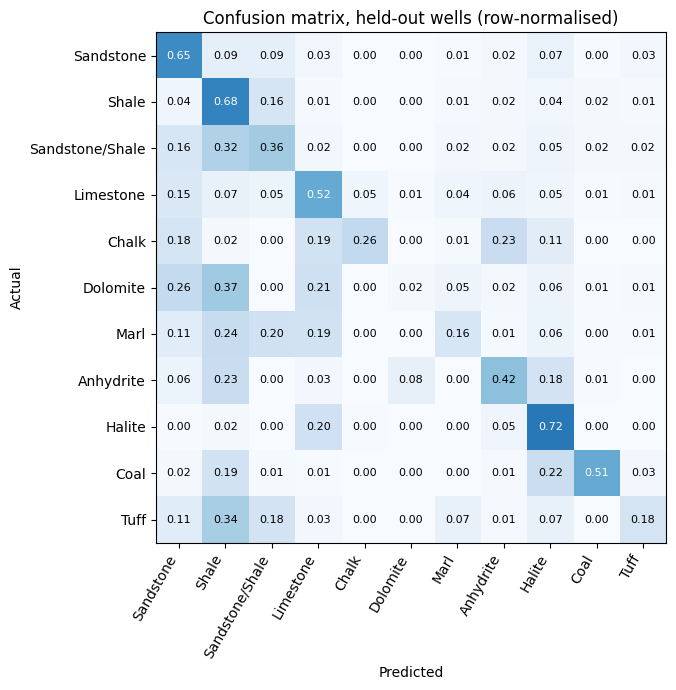

Accuracy per test well:
count    23.00
mean      0.59
std       0.18
min       0.13
25%       0.53
50%       0.63
75%       0.67
max       0.83
dtype: float64


In [13]:
cm = confusion_matrix(y_te, pred, labels=present, normalize="true")
names = [LITHO_MAP[l] for l in present]
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix, held-out wells (row-normalised)")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

per_well = (pd.Series(y_te.values == pred, index=dd.loc[is_test, "WELL"].values)
            .groupby(level=0).mean())
print("Accuracy per test well:")
print(per_well.describe().round(2))

### How stable is the score? Five random hold-outs

Macro-F1 depends on which wells land in the test set (and on which classes appear there), so a single number is not enough.

In [14]:
scores = []
for seed in range(5):
    rng = np.random.RandomState(seed)
    tw = rng.choice(dd["WELL"].unique(), size=int(0.2 * dd["WELL"].nunique()), replace=False)
    te_mask = dd["WELL"].isin(tw)
    Xtr = dd.loc[~te_mask, feats].iloc[::6]
    ytr = dd.loc[~te_mask, LABEL].astype(int).iloc[::6]
    Xte = dd.loc[te_mask, feats]
    yte = dd.loc[te_mask, LABEL].astype(int)
    mm = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=RANDOM_STATE)
    mm.fit(Xtr, ytr, sample_weight=make_weights(ytr, 0.75))
    pr = mm.predict(Xte)
    pres = [l for l in sorted(LITHO_MAP) if l in set(yte)]
    scores.append(f1_score(yte, pr, labels=pres, average="macro"))
    print(f"seed {seed}: macro-F1 = {scores[-1]:.3f} ({len(pres)} classes present)")

print(f"\nMean {np.mean(scores):.3f} +/- {np.std(scores):.3f}")

seed 0: macro-F1 = 0.434 (12 classes present)
seed 1: macro-F1 = 0.406 (9 classes present)
seed 2: macro-F1 = 0.389 (10 classes present)
seed 3: macro-F1 = 0.335 (10 classes present)
seed 4: macro-F1 = 0.385 (11 classes present)

Mean 0.390 +/- 0.032


## 7. Export wells for the interactive viewer (optional)

Exports 6 randomly chosen **held-out** wells (downsampled to every 10th sample) with logs, true labels and predictions. Wells are chosen at random on purpose, not for their results.

In [15]:
te = dd[is_test].copy()
te["PRED"] = pred
rng = np.random.RandomState(1)
names = rng.choice(te["WELL"].unique(), size=6, replace=False)

def clean(a, nd=3):
    return [None if not np.isfinite(v) else round(float(v), nd) for v in a]

out = {"synthetic": False, "classes": {str(k): v for k, v in LITHO_MAP.items()}, "wells": []}
for w in names:
    g = te[te["WELL"] == w].sort_values("DEPT").iloc[::10]
    out["wells"].append({
        "name": w, "depth": clean(g["DEPT"], 1),
        "GR": clean(g["GR"]), "RHOB": clean(g["RHOB"]), "NPHI": clean(g["NPHI"]),
        "DTC": clean(g["DTC"]), "RDEP": clean(g["RDEP"]),      # RDEP is already log10 here
        "true": [None if np.isnan(v) else int(v) for v in g[LABEL]],
        "pred": [int(v) for v in g["PRED"]],
    })
with open("well_viewer_data.json", "w") as fh:
    json.dump(out, fh)
print("Saved well_viewer_data.json")

try:
    from google.colab import files
    files.download("well_viewer_data.json")
except Exception:
    pass

Saved well_viewer_data.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Findings and limitations

**Findings**
1. Accuracy hides the real picture. "Always Shale" scores ~61% accuracy but macro-F1 of only 0.06.
2. Context features help, but window size matters: wide windows blur thin beds (Halite F1 0.53 with windows 25/100 vs 0.79 with 5/25).
3. Class weighting is a trade-off between macro-F1 and accuracy; power 0.75 was the best compromise here.
4. Filtering by label confidence backfired: ~98% of Tuff labels have the lowest confidence, so filtering removed nearly all Tuff examples.
5. Large classes (Shale, Sandstone, Limestone) are stable across splits; rare classes (Anhydrite, Halite, Dolomite) swing widely depending on which wells are held out.

**Limitations**
- Dolomite and Basement are essentially not learned (very few examples).
- "Sandstone/Shale" is a mixed class and inherently ambiguous.
- Lithology is rock type, not hydrocarbon detection.
- Results are not comparable to the official FORCE 2020 leaderboard (different metric and split).
- Single-run experiment log without variance estimates; configuration selected on the same CV used to report it.

**Next steps:** LightGBM/XGBoost with nested validation, sequence models along depth, hierarchical handling of rare classes, porosity prediction as a follow-up project.